# Pose baseline evaluation (baseline first, expand only if needed)
Order: 0-4 setup, then Part A (annotation set), manual CVAT step, Part B (quantitative, needs GT), Part C (qualitative, no GT). Part C can run before the CVAT step.
Everything that must survive a restart goes to `MyDrive/pose_baseline/`.


## 0. Mount Drive and check what exists

In [71]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
DRIVE = Path('/content/drive/MyDrive')
OUTD = DRIVE / 'pose_baseline'
OUTD.mkdir(exist_ok=True)
for p in ['datasets (1).zip', 'pose_annotation_set.zip', 'pose_baseline/pose_annotation_set_v2.zip',
          'pose_baseline/models', 'pose_baseline/pose_gt_real_val.json']:
    f = DRIVE / p
    size = f'{f.stat().st_size // 1_000_000} MB' if f.is_file() else ''
    print(f'{p:45s}', 'EXISTS' if f.exists() else 'missing', size)
!nvidia-smi --query-gpu=name,memory.total --format=csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
datasets (1).zip                              EXISTS 1600 MB
pose_annotation_set.zip                       EXISTS 54 MB
pose_baseline/pose_annotation_set_v2.zip      EXISTS 102 MB
pose_baseline/models                          EXISTS 
pose_baseline/pose_gt_real_val.json           missing 
name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Install

In [46]:
!pip -q install onnxruntime-gpu huggingface_hub ultralytics
import onnxruntime, ultralytics, cv2, numpy, sys
print('python', sys.version.split()[0], '| onnxruntime', onnxruntime.__version__,
      '| ultralytics', ultralytics.__version__, '| cv2', cv2.__version__)
print('ORT providers:', onnxruntime.get_available_providers())
!mkdir -p /content/pose_tools


python 3.13.16 | onnxruntime 1.32.0 | ultralytics 8.4.220 | cv2 4.14.0
ORT providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


## 2. Write the tools (generated from `python_scripts/pose/`, with the fixed frame selector)

In [72]:
import csv
rows = [r for r in csv.DictReader(open('/content/pose_annotation_set_v2/manifest.csv')) if '68013' in r['image']]
print(rows)

[{'image': 'images/frame_68013.jpg', 'split': 'real_train', 'block': '22', 'frame': '68013', 'x1': '535.0', 'y1': '329.0', 'x2': '939.0', 'y2': '615.0'}]


In [73]:
import csv
val = [r['image'].split('/')[-1] for r in csv.DictReader(open('/content/pose_annotation_set_v2/manifest.csv')) if r['split'] == 'real_val']
print(len(val), 'validation frames')
print(val[:5], '...', val[-3:])

62 validation frames
['frame_48701.jpg', 'frame_47274.jpg', 'frame_08314.jpg', 'frame_50189.jpg', 'frame_50349.jpg'] ... ['frame_07986.jpg', 'frame_40752.jpg', 'frame_08042.jpg']


In [74]:
import csv
rows = [r for r in csv.DictReader(open('/content/pose_annotation_set_v2/manifest.csv')) if '48533' in r['image']]
print(rows)

[{'image': 'images/frame_48533.jpg', 'split': 'real_val', 'block': '16', 'frame': '48533', 'x1': '919.0', 'y1': '400.0', 'x2': '1002.0', 'y2': '493.0'}]


In [75]:
import json, csv
S = '/content/pose_annotation_set_v2'
train = {r['image'].split('/')[-1] for r in csv.DictReader(open(S + '/manifest.csv')) if r['split'] == 'real_train'}
d = json.load(open(S + '/proposals_coco_keypoints.json'))
keep = {i['id'] for i in d['images'] if i['file_name'] in train}
d['images'] = [i for i in d['images'] if i['id'] in keep]
d['annotations'] = [a for a in d['annotations'] if a['image_id'] in keep]
json.dump(d, open(S + '/proposals_train_only.json', 'w'))
print(len(d['images']), 'images in the training-only file')

300 images in the training-only file


In [76]:
import shutil

shutil.copy(
    '/content/pose_annotation_set_v2/proposals_train_only.json',
    '/content/drive/MyDrive/pose_baseline/proposals_train_only.json'
)

'/content/drive/MyDrive/pose_baseline/proposals_train_only.json'

In [47]:
%%writefile /content/pose_tools/pose_common.py
"""Shared helpers for the pose proposal / zero-shot tools (no project imports).

Top-down model contract (from the ViTPose-L SwimXYZ model card): input (N, 3, 256, 192) float32,
ImageNet-normalised RGB crop; output (N, 17, 64, 48) heatmaps in COCO-17 order.
Pure-numpy parts (box->crop parameters, heatmap decoding, PCK) are testable without weights.
"""
from __future__ import annotations

import math
from typing import Any

import numpy as np

COCO17 = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder",
          "left_elbow", "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip",
          "left_knee", "right_knee", "left_ankle", "right_ankle"]
UPPER_BODY = [0, 5, 6, 7, 8, 9, 10]  # nose, shoulders, elbows, wrists
COCO_SKELETON = [[16, 14], [14, 12], [17, 15], [15, 13], [12, 13], [6, 12], [7, 13], [6, 7], [6, 8],
                 [7, 9], [8, 10], [9, 11], [2, 3], [1, 2], [1, 3], [2, 4], [3, 5], [4, 6], [5, 7]]
IN_W, IN_H = 192, 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def crop_params(box_xyxy: tuple[float, float, float, float], scale: float = 1.25) -> tuple[float, float, float]:
    """Return (x0, y0, s) of the crop window: window covers IN_W/s x IN_H/s pixels, box centred, padded."""
    x1, y1, x2, y2 = box_xyxy
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw, bh = max(x2 - x1, 1.0) * scale, max(y2 - y1, 1.0) * scale
    if bw / bh > IN_W / IN_H:
        bh = bw * IN_H / IN_W
    else:
        bw = bh * IN_W / IN_H
    s = IN_W / bw
    return cx - bw / 2, cy - bh / 2, s


def preprocess(frame_bgr: np.ndarray, box_xyxy: tuple[float, float, float, float]
               ) -> tuple[np.ndarray, tuple[float, float, float]]:
    import cv2  # lazy: Colab has it

    x0, y0, s = crop_params(box_xyxy)
    m = np.array([[s, 0, -x0 * s], [0, s, -y0 * s]], dtype=np.float32)
    crop = cv2.warpAffine(frame_bgr, m, (IN_W, IN_H), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    rgb = crop[:, :, ::-1].astype(np.float32) / 255.0
    rgb = (rgb - MEAN) / STD
    return rgb.transpose(2, 0, 1)[None], (x0, y0, s)


def decode_heatmaps(hm: np.ndarray, params: tuple[float, float, float]) -> np.ndarray:
    """hm: (17, H, W) -> (17, 3) [x, y, score] in image pixels (argmax, +quarter-pixel shift)."""
    k, h, w = hm.shape
    x0, y0, s = params
    out = np.zeros((k, 3), dtype=np.float32)
    for i in range(k):
        flat = int(np.argmax(hm[i]))
        iy, ix = divmod(flat, w)
        score = float(hm[i, iy, ix])
        fx, fy = float(ix), float(iy)
        if 0 < ix < w - 1:
            fx += 0.25 * np.sign(hm[i, iy, ix + 1] - hm[i, iy, ix - 1])
        if 0 < iy < h - 1:
            fy += 0.25 * np.sign(hm[i, iy + 1, ix] - hm[i, iy - 1, ix])
        cx, cy = (fx + 0.5) * IN_W / w, (fy + 0.5) * IN_H / h  # crop pixels
        out[i] = (cx / s + x0, cy / s + y0, score)
    return out


class OnnxVitPose:
    """Top-down ONNX pose model (ViTPose-L SwimXYZ export). Input name is read from the graph."""

    def __init__(self, path: str, providers: list[str] | None = None) -> None:
        import onnxruntime as ort

        self.sess = ort.InferenceSession(path, providers=providers or ["CUDAExecutionProvider",
                                                                         "CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name

    def predict(self, frame_bgr: np.ndarray, boxes: list[tuple[float, float, float, float]]) -> list[np.ndarray]:
        res = []
        for b in boxes:
            x, params = preprocess(frame_bgr, b)
            hm = self.sess.run(None, {self.input_name: x})[0][0]
            res.append(decode_heatmaps(hm, params))
        return res


def iou(a: tuple[float, ...], b: tuple[float, ...]) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def pck(pred: np.ndarray, gt: np.ndarray, box_xyxy: tuple[float, ...], thr: float,
        idx: list[int] | None = None) -> tuple[int, int]:
    """(correct, total) over GT keypoints with visibility > 0. Normaliser: longer side of the GT box."""
    norm = max(box_xyxy[2] - box_xyxy[0], box_xyxy[3] - box_xyxy[1], 1.0)
    ok = tot = 0
    for i in idx if idx is not None else range(len(gt)):
        if gt[i][2] <= 0:
            continue
        tot += 1
        if math.hypot(pred[i][0] - gt[i][0], pred[i][1] - gt[i][1]) <= thr * norm:
            ok += 1
    return ok, tot


def confident_upper(pred: np.ndarray, min_conf: float = 0.5) -> int:
    return int(sum(1 for i in UPPER_BODY if pred[i][2] >= min_conf))


def as_info(**kw: Any) -> dict[str, Any]:
    return kw


Overwriting /content/pose_tools/pose_common.py


In [48]:
%%writefile /content/pose_tools/select_annotation_frames.py
"""Pick frames to annotate with keypoints, split by contiguous frame-index BLOCKS (no video ids exist).

Source: a YOLO detection dataset (images/{train,val}, labels/{train,val}), e.g. `datasets (1).zip` unzipped.
Source train/val folders are ignored (they overlap in frame index, so they leak): all frames are pooled,
cut into blocks of --block frames, whole blocks go to real_val or real_train, and frames within --buffer of a
block boundary that touches a block of the OTHER split are dropped. Class labels are NOT used or exported.

Writes into --out: images/ (copies), manifest.csv (image,split,block,frame,x1,y1,x2,y2).
"""
from __future__ import annotations

import argparse
import csv
import random
import re
import shutil
from pathlib import Path


def frame_index(p: Path) -> int | None:
    m = re.search(r"(\d+)$", p.stem)
    return int(m.group(1)) if m else None


def read_box(label: Path, w: int, h: int) -> tuple[float, float, float, float] | None:
    boxes = []
    for ln in label.read_text(errors="replace").splitlines():
        t = ln.split()
        if len(t) == 5:
            cx, cy, bw, bh = (float(v) for v in t[1:])
            boxes.append(((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h))
    return boxes[0] if len(boxes) == 1 else None  # skip images with 0 or >1 boxes (unambiguous only)


def select(root: Path, n_val: int, n_train: int, block: int, buffer: int, spacing: int, seed: int
           ) -> list[dict]:
    items = []
    for sp in ("train", "val"):
        for img in sorted((root / "images" / sp).glob("*.jpg")):
            idx = frame_index(img)
            lbl = root / "labels" / sp / (img.stem + ".txt")
            if idx is not None and lbl.is_file():
                items.append((idx, img, lbl))
    items.sort(key=lambda t: t[0])
    count: dict[int, int] = {}
    for idx, _, _ in items:
        count[idx // block] = count.get(idx // block, 0) + 1
    blocks = sorted(count)
    rng = random.Random(seed)
    order = blocks[:]
    rng.shuffle(order)
    # Give blocks to real_val until they hold enough frames (blocks are very uneven in frame count),
    # then everything else is real_train. Frames still thin out via --spacing and the edge buffer.
    split_of: dict[int, str] = {}
    have = 0
    for b in order:
        if have < 2 * n_val:
            split_of[b] = "real_val"
            have += count[b]
        else:
            split_of[b] = "real_train"

    def near_other_split(idx: int) -> bool:
        b = idx // block
        for nb, edge in ((b - 1, idx - b * block < buffer), (b + 1, (b + 1) * block - idx <= buffer)):
            if edge and nb in split_of and split_of[nb] != split_of[b]:
                return True
        return False

    pool = [(i, im, lb) for i, im, lb in items if not near_other_split(i)]
    rng.shuffle(pool)
    chosen: list[dict] = []
    per_split = {"real_val": 0, "real_train": 0}
    target = {"real_val": n_val, "real_train": n_train}
    taken: dict[str, list[int]] = {"real_val": [], "real_train": []}
    from PIL import Image

    for idx, img, lbl in pool:
        sp = split_of[idx // block]
        if per_split[sp] >= target[sp] or any(abs(idx - t) < spacing for t in taken[sp]):
            continue
        with Image.open(img) as im:
            w, h = im.size
        box = read_box(lbl, w, h)
        if box is None:
            continue
        taken[sp].append(idx)
        per_split[sp] += 1
        chosen.append({"src": img, "split": sp, "block": idx // block, "frame": idx, "box": box})
    return chosen


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--root", type=Path, required=True)
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--n-val", type=int, default=150)
    ap.add_argument("--n-train", type=int, default=300)
    ap.add_argument("--block", type=int, default=3000, help="frames per block (unit: frame index)")
    ap.add_argument("--buffer", type=int, default=300, help="drop frames this close to a cross-split block edge")
    ap.add_argument("--spacing", type=int, default=12, help="min frame-index distance between chosen frames")
    ap.add_argument("--seed", type=int, default=42)
    a = ap.parse_args()
    chosen = select(a.root, a.n_val, a.n_train, a.block, a.buffer, a.spacing, a.seed)
    (a.out / "images").mkdir(parents=True, exist_ok=True)
    with open(a.out / "manifest.csv", "w", newline="", encoding="utf-8") as f:
        wr = csv.writer(f)
        wr.writerow(["image", "split", "block", "frame", "x1", "y1", "x2", "y2"])
        for c in chosen:
            dst = a.out / "images" / c["src"].name
            shutil.copyfile(c["src"], dst)
            wr.writerow([f"images/{dst.name}", c["split"], c["block"], c["frame"],
                         *[round(v, 1) for v in c["box"]]])
    cnt = {s: sum(1 for c in chosen if c["split"] == s) for s in ("real_val", "real_train")}
    blocks = {s: sorted({c["block"] for c in chosen if c["split"] == s}) for s in cnt}
    print("selected:", cnt, "(requested", a.n_val, "/", a.n_train, ")")
    for sp, want in (("real_val", a.n_val), ("real_train", a.n_train)):
        if cnt[sp] < want:
            print(f"WARNING: only {cnt[sp]} {sp} frames available; lower --spacing/--buffer or --block")
    print("blocks per split (disjoint by construction):", {s: len(b) for s, b in blocks.items()})
    assert not set(blocks["real_val"]) & set(blocks["real_train"])
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting /content/pose_tools/select_annotation_frames.py


In [49]:
%%writefile /content/pose_tools/make_cvat_proposals.py
"""Write model keypoint PROPOSALS as a COCO-keypoints JSON for import into CVAT (to be corrected by hand).

Input: manifest.csv from select_annotation_frames.py. Proposals are NOT ground truth: provenance is
`model_proposal_unverified` until a human has corrected the frame in CVAT.
Keypoints with score < --min-score are written as unlabelled (0, 0, 0) so the annotator adds them only if visible.

--blank-splits (default real_val): frames of these splits get NO model keypoints (box only, all points unlabelled),
so ground truth is annotated from scratch and is not biased toward the proposal model. Their provenance is `human`.
"""
from __future__ import annotations

import argparse
import csv
import json
from pathlib import Path

import cv2

from pose_common import COCO17, COCO_SKELETON, OnnxVitPose


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--set", type=Path, required=True, help="folder with manifest.csv and images/")
    ap.add_argument("--onnx", type=str, required=True, help="path to the pose .onnx file")
    ap.add_argument("--min-score", type=float, default=0.3)
    ap.add_argument("--blank-splits", nargs="*", default=["real_val"],
                    help="splits written without proposals (annotate from scratch); empty list = proposals everywhere")
    a = ap.parse_args()
    model = None  # built lazily: not needed if every split is blank
    rows = list(csv.DictReader(open(a.set / "manifest.csv", encoding="utf-8")))
    images, anns = [], []
    for i, r in enumerate(rows, start=1):
        img = cv2.imread(str(a.set / r["image"]))
        if img is None:
            raise SystemExit(f"cannot read {r['image']}")
        h, w = img.shape[:2]
        box = tuple(float(r[k]) for k in ("x1", "y1", "x2", "y2"))
        flat: list[float] = []
        n_lab = 0
        if r["split"] in a.blank_splits:
            flat = [0, 0, 0] * len(COCO17)
        else:
            if model is None:
                model = OnnxVitPose(a.onnx)
            for x, y, s in model.predict(img, [box])[0]:
                if s >= a.min_score and 0 <= x <= w and 0 <= y <= h:
                    flat += [round(float(x), 1), round(float(y), 1), 2]
                    n_lab += 1
                else:
                    flat += [0, 0, 0]
        images.append({"id": i, "file_name": Path(r["image"]).name, "width": w, "height": h})
        anns.append({"id": i, "image_id": i, "category_id": 1, "iscrowd": 0, "num_keypoints": n_lab,
                     "keypoints": flat, "bbox": [box[0], box[1], box[2] - box[0], box[3] - box[1]],
                     "area": (box[2] - box[0]) * (box[3] - box[1])})
    coco = {"images": images, "annotations": anns,
            "categories": [{"id": 1, "name": "person", "supercategory": "person",
                            "keypoints": COCO17, "skeleton": COCO_SKELETON}],
            "info": {"description": "model proposals, provenance=model_proposal_unverified"}}
    out = a.set / "proposals_coco_keypoints.json"
    out.write_text(json.dumps(coco), encoding="utf-8")
    n_blank = sum(1 for r in rows if r["split"] in a.blank_splits)
    print(f"wrote {out} ({len(images)} images; {n_blank} blank for scratch annotation, "
          f"{len(images) - n_blank} with model proposals)")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


In [50]:
%%writefile /content/pose_tools/zero_shot_eval.py
"""Zero-shot comparison of pose models on HAND-CORRECTED frames (CVAT export, COCO keypoints 1.0).

Metrics (all on GT keypoints with visibility > 0; normaliser = longer side of the GT box):
  PCK@0.05 / 0.1 / 0.2 on upper body (nose, shoulders, elbows, wrists) and on all 17,
  share of frames with >= 3 confident (>=0.5) upper-body keypoints, latency per person.
Models (any subset):
  --vitpose-onnx   ViTPose-L SwimXYZ ONNX, top-down on the GT box
  --yolo-pose      Ultralytics pose weights, full frame; the prediction with best IoU to the GT box is used
Only run on the `real_val` frames; select with --split-manifest + --split real_val. Report per camera type via --group.
"""
from __future__ import annotations

import argparse
import csv
import json
import time
from pathlib import Path

import cv2
import numpy as np

from pose_common import UPPER_BODY, OnnxVitPose, confident_upper, iou, pck

THRS = (0.05, 0.1, 0.2)


def load_gt(coco_path: Path) -> dict[str, tuple[np.ndarray, tuple[float, float, float, float]]]:
    d = json.loads(coco_path.read_text(encoding="utf-8"))
    names = {i["id"]: i["file_name"] for i in d["images"]}
    out = {}
    for a in d["annotations"]:
        k = np.array(a["keypoints"], dtype=np.float32).reshape(-1, 3)
        if k.shape[0] != 17:
            raise SystemExit(f"annotation {a['id']} has {k.shape[0]} keypoints, expected 17 (COCO order)")
        x, y, w, h = a["bbox"]
        out[Path(names[a["image_id"]]).name] = (k, (x, y, x + w, y + h))
    return out


def run_vitpose(model: OnnxVitPose, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray:
    return model.predict(img, [box])[0]


def run_yolo(model, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray | None:  # noqa: ANN001
    res = model.predict(img, verbose=False)[0]
    if res.keypoints is None or len(res.boxes) == 0:
        return None
    best, best_iou = None, 0.0
    for i, b in enumerate(res.boxes.xyxy.cpu().numpy()):
        v = iou(tuple(b), box)
        if v > best_iou:
            best, best_iou = i, v
    if best is None or best_iou < 0.3:
        return None
    xy = res.keypoints.xy[best].cpu().numpy()
    cf = res.keypoints.conf[best].cpu().numpy() if res.keypoints.conf is not None else np.ones(17)
    return np.concatenate([xy, cf[:, None]], axis=1)


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--gt", type=Path, required=True, help="CVAT export (COCO keypoints 1.0) json")
    ap.add_argument("--images", type=Path, required=True, help="folder with the images of the set")
    ap.add_argument("--manifest", type=Path, help="manifest.csv, to restrict to --split")
    ap.add_argument("--split", default="real_val")
    ap.add_argument("--group", default="", help="substring of image name defining a camera group, e.g. 'ddt'")
    ap.add_argument("--vitpose-onnx", type=str)
    ap.add_argument("--yolo-pose", type=str)
    ap.add_argument("--out", type=Path, default=Path("zero_shot_results.csv"))
    a = ap.parse_args()

    if not a.gt.is_file():
        raise SystemExit(f"GT file not found: {a.gt}. Export the corrected real_val frames from CVAT first "
                         "(see docs/POSE_ANNOTATION_GUIDE.md); this step cannot run before that.")
    gt = load_gt(a.gt)
    names = set(gt)
    if a.manifest:
        names &= {Path(r["image"]).name for r in csv.DictReader(open(a.manifest, encoding="utf-8"))
                  if r["split"] == a.split}
    if a.group:
        names = {n for n in names if a.group in n}
    names = sorted(names)
    if not names:
        raise SystemExit("no frames selected: check --split / --group / file names")
    print(f"{len(names)} frames, split={a.split}, group={a.group or 'all'}")

    runners = {}
    if a.vitpose_onnx:
        m = OnnxVitPose(a.vitpose_onnx)
        runners["vitpose_swimxyz"] = lambda im, b: run_vitpose(m, im, b)
    if a.yolo_pose:
        from ultralytics import YOLO

        y = YOLO(a.yolo_pose)
        runners[Path(a.yolo_pose).stem] = lambda im, b: run_yolo(y, im, b)
    if not runners:
        raise SystemExit("give --vitpose-onnx and/or --yolo-pose")

    rows = []
    for mname, fn in runners.items():
        acc = {(s, t): [0, 0] for s in ("upper", "all") for t in THRS}
        n_conf3 = n_missing = 0
        times = []
        for n in names:
            img = cv2.imread(str(a.images / n))
            k, box = gt[n]
            t0 = time.perf_counter()
            pred = fn(img, box)
            times.append((time.perf_counter() - t0) * 1000)
            if pred is None:
                n_missing += 1
                pred = np.zeros((17, 3), dtype=np.float32)
                pred[:, :2] = -1e6
            n_conf3 += confident_upper(pred) >= 3
            for t in THRS:
                for s, idx in (("upper", UPPER_BODY), ("all", None)):
                    ok, tot = pck(pred, k, box, t, idx)
                    acc[(s, t)][0] += ok
                    acc[(s, t)][1] += tot
        row = {"model": mname, "frames": len(names), "no_prediction": n_missing,
               "frames_ge3_confident_upper": round(n_conf3 / len(names), 3),
               "latency_ms_median_per_person": round(float(np.median(times)), 1)}
        for (s, t), (ok, tot) in acc.items():
            row[f"PCK@{t}_{s}"] = round(ok / tot, 3) if tot else None
        rows.append(row)
        print(row)
    with open(a.out, "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=list(rows[0]))
        wr.writeheader()
        wr.writerows(rows)
    print("wrote", a.out)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting /content/pose_tools/zero_shot_eval.py


## 3. Models: download ONCE to Drive, reused after restarts

In [51]:
from huggingface_hub import hf_hub_download
MODELS = OUTD / 'models'
MODELS.mkdir(exist_ok=True)
ONNX = MODELS / 'vitpose-l-swimxyz-mv.onnx'
if not ONNX.is_file():
    hf_hub_download('willalexm/vitpose-l-swimxyz', 'vitpose-l-swimxyz-mv.onnx', local_dir=str(MODELS))
print(ONNX, round(ONNX.stat().st_size / 1e9, 2), 'GB')
import onnxruntime as ort
s = ort.InferenceSession(str(ONNX), providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
print('inputs ', [(i.name, i.shape) for i in s.get_inputs()])
print('outputs', [(o.name, o.shape) for o in s.get_outputs()])
print('session providers', s.get_providers())
del s


/content/drive/MyDrive/pose_baseline/models/vitpose-l-swimxyz-mv.onnx 1.23 GB
inputs  [('input', ['batch', 3, 256, 192])]
outputs [('heatmaps', ['batch', 17, 'Convheatmaps_dim_2', 'Convheatmaps_dim_3'])]
session providers ['CUDAExecutionProvider', 'CPUExecutionProvider']


In [52]:
# YOLO11s-pose (about 20 MB, COCO-pose pretrained) for the comparison; kept next to the ONNX on Drive
import shutil
from ultralytics import YOLO
YOLO_PT = MODELS / 'yolo11s-pose.pt'
if not YOLO_PT.is_file():
    YOLO('yolo11s-pose.pt')
    shutil.move('yolo11s-pose.pt', YOLO_PT)
print(YOLO_PT, round(YOLO_PT.stat().st_size / 1e6, 1), 'MB')


/content/drive/MyDrive/pose_baseline/models/yolo11s-pose.pt 20.4 MB


## 4. Dataset: one zip copied to local disk and unzipped

In [53]:
import shutil, zipfile
ROOT = Path('/content/pose_ds/datasets')
if not ROOT.is_dir():
    shutil.copyfile(DRIVE / 'datasets (1).zip', '/content/pose_ds.zip')
    with zipfile.ZipFile('/content/pose_ds.zip') as z:
        z.extractall('/content/pose_ds')
print('images:', sum(1 for _ in (ROOT / 'images').rglob('*.jpg')))


images: 5613


---
# Part A: annotation set v2
Skip A1-A3 if `pose_baseline/pose_annotation_set_v2.zip` already exists.

In [69]:
!cd /content && zip -qr "/content/drive/MyDrive/pose_baseline/pose_annotation_set_v2.zip" pose_annotation_set_v2
print('saved')

saved


In [70]:
import zipfile, json
z = zipfile.ZipFile('/content/drive/MyDrive/pose_baseline/pose_annotation_set_v2.zip')
d = json.loads(z.read('pose_annotation_set_v2/proposals_coco_keypoints.json'))
blank = sum(1 for a in d['annotations'] if a['num_keypoints'] == 0)
print('images in zip:', len(d['images']), '| annotations with no keypoints:', blank)

images in zip: 362 | annotations with no keypoints: 62


In [54]:
# A1. select frames with the fixed selector (150 real_val + 300 real_train, split by frame-index block)
SET = Path('/content/pose_annotation_set_v2')
!cd /content/pose_tools && python select_annotation_frames.py --root "{ROOT}" --out "{SET}" --n-val 150 --n-train 300


selected: {'real_val': 62, 'real_train': 300} (requested 150 / 300 )
blocks per split (disjoint by construction): {'real_val': 4, 'real_train': 8}


In [65]:
%%writefile /content/pose_tools/make_cvat_proposals.py
"""Write model keypoint PROPOSALS as a COCO-keypoints JSON for import into CVAT (to be corrected by hand).

--blank-splits (default real_val): frames of these splits get NO model keypoints (box only, all points unlabelled),
so ground truth is annotated from scratch and is not biased toward the proposal model.
"""
from __future__ import annotations

import argparse
import csv
import json
from pathlib import Path

import cv2

from pose_common import COCO17, COCO_SKELETON, OnnxVitPose


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--set", type=Path, required=True, help="folder with manifest.csv and images/")
    ap.add_argument("--onnx", type=str, required=True, help="path to the pose .onnx file")
    ap.add_argument("--min-score", type=float, default=0.3)
    ap.add_argument("--blank-splits", nargs="*", default=["real_val"],
                    help="splits written without proposals (annotate from scratch); empty list = proposals everywhere")
    a = ap.parse_args()
    model = None  # built lazily: not needed if every split is blank
    rows = list(csv.DictReader(open(a.set / "manifest.csv", encoding="utf-8")))
    images, anns = [], []
    for i, r in enumerate(rows, start=1):
        img = cv2.imread(str(a.set / r["image"]))
        if img is None:
            raise SystemExit(f"cannot read {r['image']}")
        h, w = img.shape[:2]
        box = tuple(float(r[k]) for k in ("x1", "y1", "x2", "y2"))
        flat: list[float] = []
        n_lab = 0
        if r["split"] in a.blank_splits:
            flat = [0, 0, 0] * len(COCO17)
        else:
            if model is None:
                model = OnnxVitPose(a.onnx)
            for x, y, s in model.predict(img, [box])[0]:
                if s >= a.min_score and 0 <= x <= w and 0 <= y <= h:
                    flat += [round(float(x), 1), round(float(y), 1), 2]
                    n_lab += 1
                else:
                    flat += [0, 0, 0]
        images.append({"id": i, "file_name": Path(r["image"]).name, "width": w, "height": h})
        anns.append({"id": i, "image_id": i, "category_id": 1, "iscrowd": 0, "num_keypoints": n_lab,
                     "keypoints": flat, "bbox": [box[0], box[1], box[2] - box[0], box[3] - box[1]],
                     "area": (box[2] - box[0]) * (box[3] - box[1])})
    coco = {"images": images, "annotations": anns,
            "categories": [{"id": 1, "name": "person", "supercategory": "person",
                            "keypoints": COCO17, "skeleton": COCO_SKELETON}],
            "info": {"description": "model proposals, provenance=model_proposal_unverified"}}
    out = a.set / "proposals_coco_keypoints.json"
    out.write_text(json.dumps(coco), encoding="utf-8")
    n_blank = sum(1 for r in rows if r["split"] in a.blank_splits)
    print(f"wrote {out} ({len(images)} images; {n_blank} blank for scratch annotation, "
          f"{len(images) - n_blank} with model proposals)")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

Overwriting /content/pose_tools/make_cvat_proposals.py


In [66]:
# A2. COCO keypoints file for CVAT. real_val frames are written BLANK (annotate from scratch, no model bias);
# real_train frames get ViTPose proposals. Re-run A3 afterwards to refresh the zip on Drive.
!cd /content/pose_tools && python make_cvat_proposals.py --set "{SET}" --onnx "{ONNX}" --blank-splits real_val


wrote /content/pose_annotation_set_v2/proposals_coco_keypoints.json (362 images; 62 blank for scratch annotation, 300 with model proposals)


In [67]:
# A3. save the set to Drive (download this zip for CVAT)
!cd /content && zip -qr "{OUTD}/pose_annotation_set_v2.zip" pose_annotation_set_v2
print('blank-splits' in open('/content/pose_tools/make_cvat_proposals.py').read())


True


**Manual step:** correct the `real_val` frames in CVAT (see `docs/POSE_ANNOTATION_GUIDE.md`). Minimum first baseline: 60 frames covering upright, horizontal and occluded swimmers. Export *COCO Keypoints 1.0* containing only corrected frames, upload it as `MyDrive/pose_baseline/pose_gt_real_val.json`.

---
# Part B: quantitative baseline (only after the GT file exists)

In [57]:
# B0. restore the set after a restart, check the ground truth
import json, zipfile
SET = Path('/content/pose_annotation_set_v2')
if not SET.is_dir():
    with zipfile.ZipFile(OUTD / 'pose_annotation_set_v2.zip') as z:
        z.extractall('/content')
GT = OUTD / 'pose_gt_real_val.json'
assert GT.is_file(), f'No ground truth yet: {GT}. Do the CVAT step first.'
g = json.loads(GT.read_text())
print('GT images:', len(g['images']), '| annotations:', len(g['annotations']))


AssertionError: No ground truth yet: /content/drive/MyDrive/pose_baseline/pose_gt_real_val.json. Do the CVAT step first.

In [ ]:
# B1. ViTPose-L SwimXYZ vs YOLO11s-pose: same frames, same GT, same metric
!cd /content/pose_tools && python zero_shot_eval.py --gt "{GT}" --images "{SET}/images" --manifest "{SET}/manifest.csv" --split real_val --vitpose-onnx "{ONNX}" --yolo-pose "{YOLO_PT}" --out "{OUTD}/zero_shot_results.csv"


ViTPose runs top-down on the GT box; YOLO11s-pose runs on the full frame and its best-IoU person (IoU >= 0.3) is used, misses count as wrong. Frames and metric are identical; the box source is not, and the report says so.

---
# Part C: qualitative only (no ground truth)

In [58]:
# C1. runs of near-consecutive frames (frame-index gap <= 3) for stability and overlays
import re
import numpy as np
def fidx(p):
    return int(re.search(r'(\d+)$', p.stem).group(1))
frames = sorted([p for sp in ('train', 'val') for p in (ROOT / 'images' / sp).glob('*.jpg')], key=fidx)
runs, cur = [], [frames[0]]
for a, b in zip(frames, frames[1:]):
    if fidx(b) - fidx(a) <= 3:
        cur.append(b)
    else:
        if len(cur) >= 8:
            runs.append(cur)
        cur = [b]
runs = sorted(runs, key=len, reverse=True)
print(len(runs), 'runs of >= 8 near-consecutive frames; longest:', [len(r) for r in runs[:10]])


22 runs of >= 8 near-consecutive frames; longest: [1871, 1653, 245, 196, 156, 113, 112, 105, 103, 103]


In [59]:
# C2. both models on up to 8 runs x 12 frames; box = the dataset's own box (one person per image)
import sys, time, cv2
sys.path.insert(0, '/content/pose_tools')
from pose_common import OnnxVitPose, iou, UPPER_BODY
from ultralytics import YOLO
vit = OnnxVitPose(str(ONNX))
yolo = YOLO(str(YOLO_PT))
def gt_box(img_path, w, h):
    lbl = img_path.parent.parent.parent / 'labels' / img_path.parent.name / (img_path.stem + '.txt')
    t = lbl.read_text().split()
    cx, cy, bw, bh = (float(v) for v in t[1:5])
    return ((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h)
def yolo_pred(img, box):
    r = yolo.predict(img, verbose=False)[0]
    if r.keypoints is None or len(r.boxes) == 0:
        return None
    ious = [iou(tuple(b), box) for b in r.boxes.xyxy.cpu().numpy()]
    i = int(np.argmax(ious))
    if ious[i] < 0.3:
        return None
    return np.concatenate([r.keypoints.xy[i].cpu().numpy(), r.keypoints.conf[i].cpu().numpy()[:, None]], 1)
RES = {}
lat = {'vitpose': [], 'yolo': []}
for run in runs[:8]:
    for p in run[:12]:
        img = cv2.imread(str(p))
        h, w = img.shape[:2]
        box = gt_box(p, w, h)
        t0 = time.perf_counter(); kv = vit.predict(img, [box])[0]; lat['vitpose'].append(time.perf_counter() - t0)
        t0 = time.perf_counter(); ky = yolo_pred(img, box); lat['yolo'].append(time.perf_counter() - t0)
        RES[p] = (box, kv, ky)
for k, v in lat.items():
    print(k, 'median ms per frame', round(1000 * float(np.median(v[1:])), 1))


vitpose median ms per frame 33.6
yolo median ms per frame 12.4


In [60]:
# C3. stability: frame-to-frame keypoint jump / box height, after removing box-centre motion.
# Real body motion is included, so this is an UPPER bound on jitter: compare models, not absolute values.
def jumps(idx):
    out = []
    for run in runs[:8]:
        seq = [RES[p] for p in run[:12] if p in RES]
        for r0, r1 in zip(seq, seq[1:]):
            b0, b1, k0, k1 = r0[0], r1[0], r0[idx], r1[idx]
            if k0 is None or k1 is None:
                continue
            c0 = np.array([(b0[0] + b0[2]) / 2, (b0[1] + b0[3]) / 2])
            c1 = np.array([(b1[0] + b1[2]) / 2, (b1[1] + b1[3]) / 2])
            hgt = max(b0[3] - b0[1], 1)
            for i in UPPER_BODY:
                if k0[i][2] >= 0.5 and k1[i][2] >= 0.5:
                    out.append(np.linalg.norm((k1[i][:2] - c1) - (k0[i][:2] - c0)) / hgt)
    return np.array(out)
for m, idx in (('vitpose', 1), ('yolo', 2)):
    j = jumps(idx)
    n = len(RES)
    none = sum(1 for v in RES.values() if v[idx] is None)
    conf3 = sum(1 for v in RES.values() if v[idx] is not None and sum(v[idx][i][2] >= 0.5 for i in UPPER_BODY) >= 3)
    jt = f'median jump {np.median(j):.3f}, p90 {np.percentile(j, 90):.3f} of box height ({len(j)} pairs)' if len(j) else 'no confident consecutive keypoints'
    print(f'{m:8s} frames {n} | no prediction {none} | >=3 confident upper-body points {conf3} | {jt}')


vitpose  frames 96 | no prediction 0 | >=3 confident upper-body points 80 | median jump 0.016, p90 0.067 of box height (407 pairs)
yolo     frames 96 | no prediction 2 | >=3 confident upper-body points 94 | median jump 0.031, p90 0.149 of box height (551 pairs)


saved /content/drive/MyDrive/pose_baseline/overlay_run0.jpg


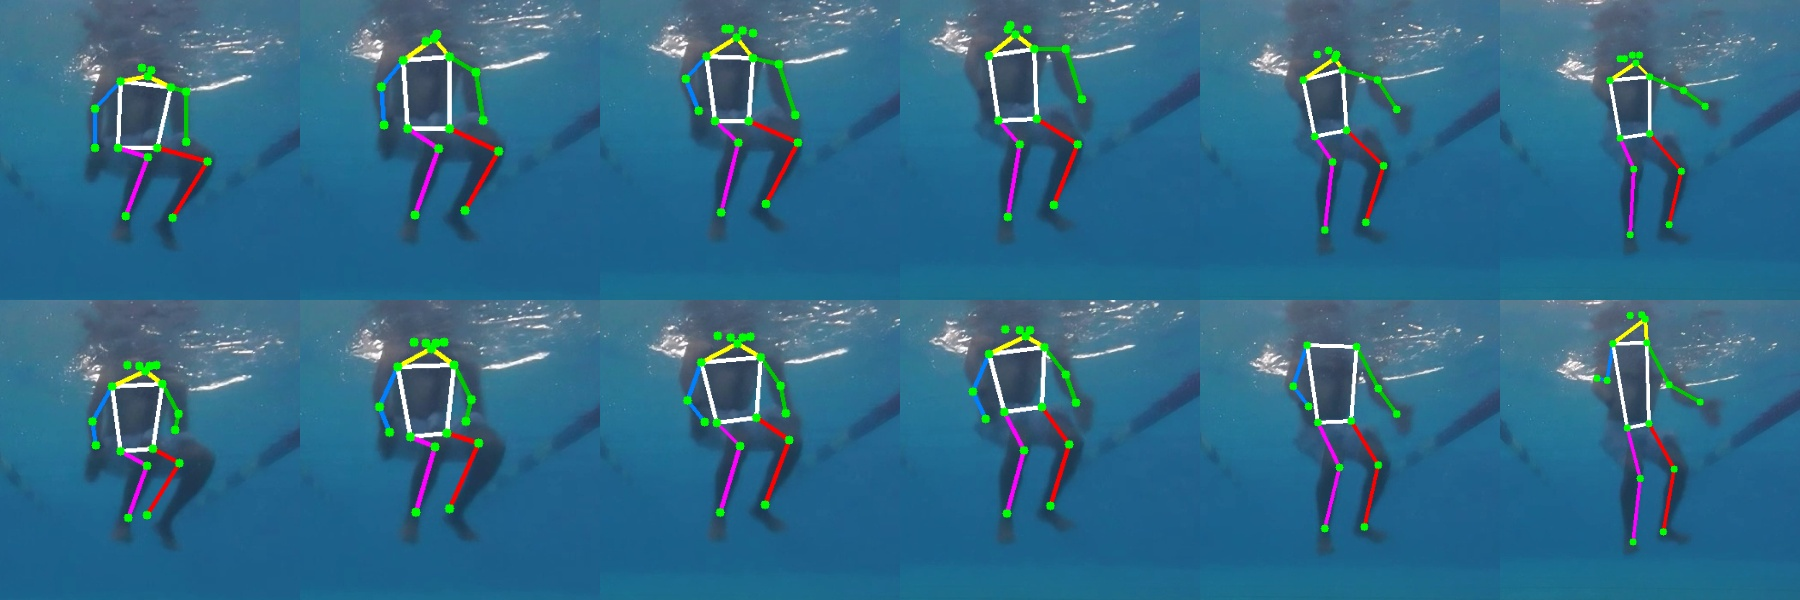

saved /content/drive/MyDrive/pose_baseline/overlay_run1.jpg


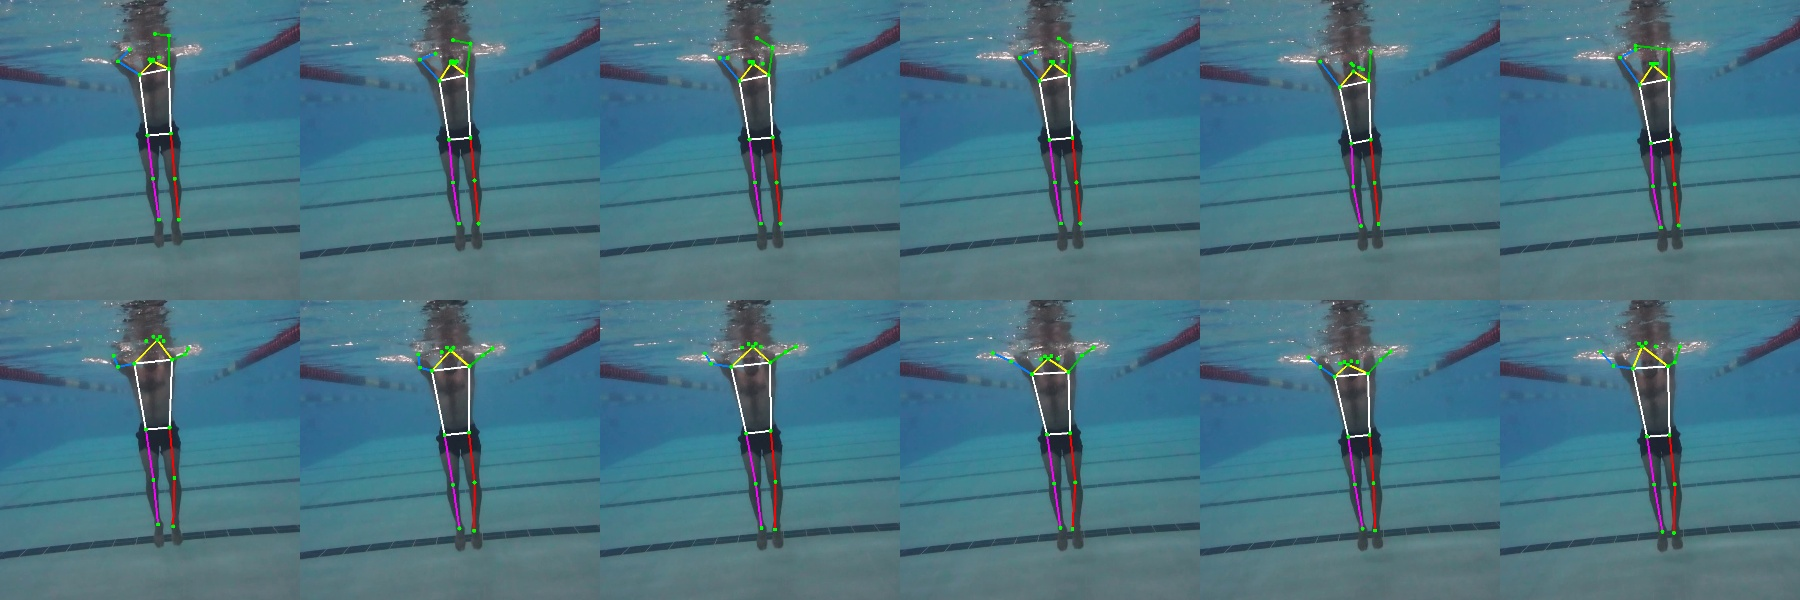

In [61]:
# C4. skeleton overlays: 2 runs x 6 frames; top row ViTPose-L SwimXYZ, bottom row YOLO11s-pose; saved to Drive
SK = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]
COL = {'head': (0, 255, 255), 'torso': (255, 255, 255), 'larm': (0, 200, 0), 'rarm': (255, 128, 0),
       'lleg': (0, 0, 255), 'rleg': (255, 0, 255)}
def sec(a, b):
    s = {a, b}
    if s & {7, 9}: return 'larm'
    if s & {8, 10}: return 'rarm'
    if s & {13, 15}: return 'lleg'
    if s & {14, 16}: return 'rleg'
    if 0 in s: return 'head'
    return 'torso'
def draw(img, k, box, thr=0.3):
    im = img.copy()
    if k is not None:
        for a, b in SK:
            if k[a][2] >= thr and k[b][2] >= thr:
                cv2.line(im, tuple(int(v) for v in k[a][:2]), tuple(int(v) for v in k[b][:2]), COL[sec(a, b)], 3)
        for x, y, c in k:
            if c >= thr:
                cv2.circle(im, (int(x), int(y)), 5, (0, 255, 0), -1)
    x1, y1, x2, y2 = (int(v) for v in box)
    cx, cy, r = (x1 + x2) // 2, (y1 + y2) // 2, int(max(x2 - x1, y2 - y1) * 0.75)
    crop = im[max(0, cy - r):cy + r, max(0, cx - r):cx + r]
    return cv2.resize(crop, (300, 300))
from IPython.display import Image, display
for n, run in enumerate(runs[:2]):
    ps = [p for p in run[:12:2] if p in RES][:6]
    top = np.hstack([draw(cv2.imread(str(p)), RES[p][1], RES[p][0]) for p in ps])
    bot = np.hstack([draw(cv2.imread(str(p)), RES[p][2], RES[p][0]) for p in ps])
    out = OUTD / f'overlay_run{n}.jpg'
    cv2.imwrite(str(out), np.vstack([top, bot]))
    print('saved', out)
    display(Image(str(out)))


Part C numbers are not accuracy: there is no ground truth, and body motion between frames is included in the jump measure.